In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

In [2]:
INPUT_FILE = r"E:\SEM5\DPTLM\DTPLM_Project\college_predictor\Data\MHTCET_Engineering_CutOffs_2022-2025.csv"
df = pd.read_csv(INPUT_FILE)

print("Original shape:", df.shape)
display(df.head())

Original shape: (282936, 15)


,Year,AcademicYear,CAPRound,CollegeCode,CollegeCode_Norm,CollegeName,BranchCode,BranchCode_Norm,BranchName,Status,Level,Category,Stage,Rank,Percentile
0,2022,2022-23,I,1002,1002,"Government College of Engineering, Amravati",100219110,100219110,Civil Engineering,Government Autonomous,State Level,GOPENS,I,40678,77.849577
1,2022,2022-23,I,1002,1002,"Government College of Engineering, Amravati",100219110,100219110,Civil Engineering,Government Autonomous,State Level,GSCS,I,55830,68.298536
2,2022,2022-23,I,1002,1002,"Government College of Engineering, Amravati",100219110,100219110,Civil Engineering,Government Autonomous,State Level,GSTS,I,86718,43.316750
3,2022,2022-23,I,1002,1002,"Government College of Engineering, Amravati",100219110,100219110,Civil Engineering,Government Autonomous,State Level,GVJS,I,45691,74.510640
4,2022,2022-23,I,1002,1002,"Government College of Engineering, Amravati",100219110,100219110,Civil Engineering,Government Autonomous,State Level,GNT1S,I,41586,77.066692


In [5]:
clean = df.copy()

# STANDARDIZE COLUMN NAMES

In [6]:
clean.columns = (
    clean.columns
    .str.strip()
    .str.replace("\n", " ", regex=False)
    .str.replace(r"\s+", "_", regex=True)
)

print("\nColumns:")
print(clean.columns.tolist())


Columns:
['Year', 'AcademicYear', 'CAPRound', 'CollegeCode', 'CollegeCode_Norm', 'CollegeName', 'BranchCode', 'BranchCode_Norm', 'BranchName', 'Status', 'Level', 'Category', 'Stage', 'Rank', 'Percentile']


# CLEAN TEXT COLUMNS

In [7]:
text_columns = clean.select_dtypes(include="object").columns

for col in text_columns:
    clean[col] = (
        clean[col]
        .astype("string")
        .str.replace("\r", " ", regex=False)
        .str.replace("\n", " ", regex=False)
        .str.replace("\t", " ", regex=False)
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )

print("\nText cleaning completed.")


Text cleaning completed.


# STANDARDIZE IMPORTANT COLUMN NAMES

In [8]:
# Year
clean["Year"] = pd.to_numeric(clean["Year"], errors="coerce").astype("Int64")

# Rank
clean["Rank"] = pd.to_numeric(clean["Rank"], errors="coerce")

# Percentile
clean["Percentile"] = pd.to_numeric(clean["Percentile"], errors="coerce")

# YEAR MAPPING

In [9]:
academic_year_map = {
    2022: "2022-23",
    2023: "2023-24",
    2024: "2024-25",
    2025: "2025-26"
}

clean["AcademicYear"] = clean["Year"].map(academic_year_map)

# NORMALIZE CAP ROUNDS

In [10]:
clean["CAPRound"] = (
    clean["CAPRound"]
    .astype("string")
    .str.strip()
    .str.upper()
)

print("\nCAP rounds:")
print(clean["CAPRound"].value_counts(dropna=False))


CAP rounds:
CAPRound
I      109863
II     102316
III     57170
IV      13587
Name: count, dtype: Int64


# NORMALIZE STAGES

In [11]:
clean["Stage"] = (
    clean["Stage"]
    .astype("string")
    .str.replace("\n", " ", regex=False)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

print("\nStages:")
print(clean["Stage"].value_counts(dropna=False))


Stages:
Stage
I                230528
VII               28285
I-Non PWD         10218
I-Non Defence      6808
II                 5276
MH                 1821
Name: count, dtype: Int64


# NORMALIZE COLLEGE CODE

In [12]:
clean["CollegeCode"] = (
    clean["CollegeCode"]
    .astype("string")
    .str.strip()
)

# Keep leading zeros if they exist
clean["CollegeCode"] = clean["CollegeCode"].str.upper()

# NORMALIZE COLLEGE NAMES

In [13]:
clean["CollegeName"] = (
    clean["CollegeName"]
    .astype("string")
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# NORMALIZE BRANCH CODE

In [14]:
clean["BranchCode"] = (
    clean["BranchCode"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# NORMALIE BRANC NAMES

In [15]:
clean["BranchName"] = (
    clean["BranchName"]
    .astype("string")
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)


# NORMALIZE CATEGORIES

In [16]:
clean["Category"] = (
    clean["Category"]
    .astype("string")
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
    .str.upper()
)

# NORMALIZE STATUS

In [17]:
if "Status" in clean.columns:
    clean["Status"] = (
        clean["Status"]
        .astype("string")
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
        .str.upper()
    )

# NORMALIZE LEVELS

In [18]:
if "Level" in clean.columns:
    clean["Level"] = (
        clean["Level"]
        .astype("string")
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
        .str.upper()
    )

# CHECK MISSING VALUES

In [19]:
print("\nMissing values:")
missing = clean.isna().sum()
display(missing[missing > 0].sort_values(ascending=False))


Missing values:


Series([], dtype: int64)

# CHECK INVALID NUMERIC VALUES

In [20]:
invalid_rank = clean[
    (clean["Rank"].isna()) |
    (clean["Rank"] <= 0)
]

invalid_percentile = clean[
    (clean["Percentile"].isna()) |
    (clean["Percentile"] < 0) |
    (clean["Percentile"] > 100)
]

print("Invalid Rank records:", len(invalid_rank))

Invalid Rank records: 0


In [21]:
zero_percentile = clean[clean["Percentile"] == 0]

print("\nPercentile = 0 records:", len(zero_percentile))

display(
    zero_percentile[
        [
            "Year",
            "CAPRound",
            "CollegeCode",
            "CollegeName",
            "BranchCode",
            "BranchName",
            "Category",
            "Stage",
            "Rank",
            "Percentile"
        ]
    ].head(20)
)


Percentile = 0 records: 62


,Year,CAPRound,CollegeCode,CollegeName,BranchCode,BranchName,Category,Stage,Rank,Percentile
108754,2024,I,2021,"University Department of Chemical Technology, ...",202150310,Food Technology,TFWS,I,8622,0.0
111769,2024,I,3036,"Institute of Chemical Technology, Matunga, Mumbai",303651310,Pharmaceuticals Chemistry and Technology,TFWS,I,1102,0.0
111808,2024,I,3036,"Institute of Chemical Technology, Matunga, Mumbai",303653410,Food Engineering and Technology,TFWS,I,2482,0.0
116954,2024,I,4123,"Lokmanya Tilak Jankalyan Shikshan Sanstha, Pri...",412308210,Bio Technology,TFWS,I,19755,0.0
117908,2024,I,4151,Tulsiramji Gaikwad Patil College of Engineerin...,415108210,Bio Technology,TFWS,I,20112,0.0
119355,2024,I,5003,"University Institute of Chemical Technology, N...",500350310,Food Technology,TFWS,I,15755,0.0
128395,2024,I,6222,Dattajirao Kadam Technical Education Society's...,622257010,Fashion Technology,TFWS,I,40128,0.0
128734,2024,I,6267,Kolhapur Institute of Technology's College of ...,626708210,Bio Technology,TFWS,I,6963,0.0
130017,2024,I,6274,Pune Vidyarthi Griha's College of Engineering ...,627484110,Printing and Packing Technology,TFWS,I,29982,0.0
137295,2024,I,14005,Laxminarayan Innovation Technological Universi...,1400550310,Food Technology,TFWS,I,5776,0.0


In [22]:
clean["IsNonCETPercentile"] = (
    clean["Percentile"] == 0
)

print(
    "\nNon-CET/special percentile records:",
    clean["IsNonCETPercentile"].sum()
)


Non-CET/special percentile records: 62


In [23]:
before_duplicates = len(clean)

clean = clean.drop_duplicates()

after_duplicates = len(clean)

print("\nExact duplicates removed:", before_duplicates - after_duplicates)
print("Shape after exact duplicate removal:", clean.shape)


Exact duplicates removed: 0
Shape after exact duplicate removal: (282936, 16)


In [24]:
logical_columns = [
    "Year",
    "CAPRound",
    "CollegeCode",
    "BranchCode",
    "Category",
    "Stage"
]

logical_counts = (
    clean
    .groupby(logical_columns, dropna=False)
    .size()
    .reset_index(name="RecordCount")
)

multi_record_groups = logical_counts[
    logical_counts["RecordCount"] > 1
]

print(
    "\nLogical groups containing multiple records:",
    len(multi_record_groups)
)

print(
    "Records belonging to these groups:",
    multi_record_groups["RecordCount"].sum()
)


Logical groups containing multiple records: 4425
Records belonging to these groups: 8860


In [25]:
college_conflicts = (
    clean
    .groupby("CollegeCode")["CollegeName"]
    .nunique()
    .reset_index(name="UniqueCollegeNames")
)

college_conflicts = college_conflicts[
    college_conflicts["UniqueCollegeNames"] > 1
]

print("\nCollege codes with multiple names:", len(college_conflicts))


branch_conflicts = (
    clean
    .groupby("BranchCode")["BranchName"]
    .nunique()
    .reset_index(name="UniqueBranchNames")
)

branch_conflicts = branch_conflicts[
    branch_conflicts["UniqueBranchNames"] > 1
]

print("Branch codes with multiple names:", len(branch_conflicts))



College codes with multiple names: 28
Branch codes with multiple names: 2


In [26]:
clean["Flag_InvalidRank"] = (
    clean["Rank"].isna() |
    (clean["Rank"] <= 0)
)

clean["Flag_InvalidPercentile"] = (
    clean["Percentile"].isna() |
    (clean["Percentile"] < 0) |
    (clean["Percentile"] > 100)
)

clean["Flag_ZeroPercentile"] = (
    clean["Percentile"] == 0
)

clean["Flag_CollegeCodeConflict"] = (
    clean["CollegeCode"].isin(
        college_conflicts["CollegeCode"]
    )
)

clean["Flag_BranchCodeConflict"] = (
    clean["BranchCode"].isin(
        branch_conflicts["BranchCode"]
    )
)

In [28]:
clean["DataQualityStatus"] = np.select(
    [
        clean["Flag_InvalidRank"],
        clean["Flag_InvalidPercentile"],
        clean["Flag_CollegeCodeConflict"],
        clean["Flag_BranchCodeConflict"],
        clean["Flag_ZeroPercentile"]
    ],
    [
        "INVALID_RANK",
        "INVALID_PERCENTILE",
        "COLLEGE_CODE_CONFLICT",
        "BRANCH_CODE_CONFLICT",
        "NON_CET_OR_SPECIAL"
    ],
    default="VALID"
)


In [29]:
print("\n================ DATA QUALITY SUMMARY ================")

print(
    clean["DataQualityStatus"]
    .value_counts(dropna=False)
)


================ DATA QUALITY SUMMARY ================
DataQualityStatus
VALID                    260009
COLLEGE_CODE_CONFLICT     22712
BRANCH_CODE_CONFLICT        165
NON_CET_OR_SPECIAL           50
Name: count, dtype: int64


# CLEAN PRIDICTOR DATASET

In [30]:
predictor_columns = [
    "Year",
    "AcademicYear",
    "CAPRound",
    "CollegeCode",
    "CollegeName",
    "BranchCode",
    "BranchName",
    "Category",
    "Stage",
    "Rank",
    "Percentile",
    "IsNonCETPercentile",
    "DataQualityStatus"
]

# Add optional columns if they exist
for col in ["Status", "Level"]:
    if col in clean.columns:
        predictor_columns.append(col)

predictor_df = clean[predictor_columns].copy()

# SEPARATE VALID AND SPECIAL RECORDS

In [31]:
valid_predictor_df = predictor_df[
    predictor_df["DataQualityStatus"] == "VALID"
].copy()

special_records_df = predictor_df[
    predictor_df["DataQualityStatus"] != "VALID"
].copy()


print("\nFinal datasets:")
print("Cleaned:", predictor_df.shape)
print("Valid predictor:", valid_predictor_df.shape)
print("Flagged/special:", special_records_df.shape)


Final datasets:
Cleaned: (282936, 15)
Valid predictor: (260009, 15)
Flagged/special: (22927, 15)


In [32]:
predictor_df.to_csv(
    "MHTCET_Cleaned_Data.csv",
    index=False
)

valid_predictor_df.to_csv(
    "MHTCET_Predictor_Data.csv",
    index=False
)

special_records_df.to_csv(
    "MHTCET_Flagged_Records.csv",
    index=False
)

college_conflicts.to_csv(
    "MHTCET_College_Code_Conflicts.csv",
    index=False
)

branch_conflicts.to_csv(
    "MHTCET_Branch_Code_Conflicts.csv",
    index=False
)

print("\nFiles saved successfully.")


Files saved successfully.


# Understanding Historical Cutoff

In [2]:
# import numpy as np
# import pandas as pd

df = pd.read_csv(r"E:\SEM5\DPTLM\DTPLM_Project\college_predictor\Data\MHTCET_Cleaned_Data.csv")

## Logical Cutoff Groups

In [3]:
group_cols = [
    "Year",
    "CAPRound",
    "CollegeCode",
    "CollegeName",
    "BranchCode",
    "BranchName",
    "Category",
    "Stage"
]

print("Dataset:", df.shape)

Dataset: (282936, 15)


## Group Statistics

In [4]:
cutoff_analysis = (
    df.groupby(group_cols, dropna=False)
      .agg(
          Records=("Percentile", "size"),

          HighestPercentile=("Percentile", "max"),
          LowestPercentile=("Percentile", "min"),
          MedianPercentile=("Percentile", "median"),

          BestRank=("Rank", "min"),
          WorstRank=("Rank", "max"),
          MedianRank=("Rank", "median"),

          UniquePercentiles=("Percentile", "nunique"),
          UniqueRanks=("Rank", "nunique")
      )
      .reset_index()
)

display(cutoff_analysis.head())

,Year,CAPRound,CollegeCode,CollegeName,BranchCode,BranchName,Category,Stage,Records,HighestPercentile,LowestPercentile,MedianPercentile,BestRank,WorstRank,MedianRank,UniquePercentiles,UniqueRanks
0,2022,I,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,DEFOPENS,I,1,42.794675,42.794675,42.794675,88218,88218,88218.0,1,1
1,2022,I,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,DEFROBCS,I,1,32.499271,32.499271,32.499271,98060,98060,98060.0,1,1
2,2022,I,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,EWS,I,1,70.213583,70.213583,70.213583,52672,52672,52672.0,1,1
3,2022,I,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,GNT1S,I,1,77.066692,77.066692,77.066692,41586,41586,41586.0,1,1
4,2022,I,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,GNT2S,I,1,70.926321,70.926321,70.926321,51711,51711,51711.0,1,1


## Multi Record Groups

In [5]:
multi = cutoff_analysis[
    cutoff_analysis["Records"] > 1
].copy()

print("Multi-record groups:", len(multi))

display(multi.head(30))

Multi-record groups: 4425


,Year,CAPRound,CollegeCode,CollegeName,BranchCode,BranchName,Category,Stage,Records,HighestPercentile,LowestPercentile,MedianPercentile,BestRank,WorstRank,MedianRank,UniquePercentiles,UniqueRanks
148,2022,I,1005,"Sant Gadge Baba Amravati University,Amravati",100552710,Petro Chemical Engineering,GOPENH,I,2,59.682905,19.107271,39.395088,67801,110078,88939.5,2,2
165,2022,I,1012,"Government College of Engineering,Yavatmal",101219110,Civil Engineering,GSTH,I,2,26.900779,12.935323,19.918051,103344,114482,108913.0,2,2
215,2022,I,1012,"Government College of Engineering,Yavatmal",101229310,Electrical Engineering,GSTH,I,2,35.394570,12.429947,23.912259,95997,114955,105476.0,2,2
386,2022,I,1105,Prof. Ram Meghe Institute of Technology & Rese...,110519110,Civil Engineering,GOPENO,I,2,34.666856,10.198231,22.432544,96617,116713,106665.0,2,2
432,2022,I,1105,Prof. Ram Meghe Institute of Technology & Rese...,110524210,Computer Science and Engineering,PWDOPENH,I,2,39.312868,0.435132,19.874000,92097,122436,107266.5,2,2
540,2022,I,1107,P. R. Pote (Patil) Education & Welfare Trust's...,110719110,Civil Engineering,GOBCO,I,2,39.158254,8.595120,23.876687,92464,117696,105080.0,2,2
770,2022,I,1114,Sipna Shikshan Prasarak Mandal College of Engi...,111461210,Mechanical Engineering,GOPENO,I,2,39.608181,22.487107,31.047644,90798,107198,98998.0,2,2
850,2022,I,1117,Janata Shikshan Prasarak Mandal’s Babasaheb Na...,111719110,Civil Engineering,GOPENO,I,2,35.394570,32.212708,33.803639,96072,99053,97562.5,2,2
900,2022,I,1117,Janata Shikshan Prasarak Mandal’s Babasaheb Na...,111761210,Mechanical Engineering,GOPENO,I,2,26.314043,5.914393,16.114218,103772,119229,111500.5,2,2
968,2022,I,1119,Paramhansa Ramkrishna Maunibaba Shikshan Santh...,111937210,Electronics and Telecommunication Engg,GOBCO,I,2,35.978039,4.212419,20.095229,94799,120411,107605.0,2,2


## Spread Withing Groups

In [6]:
multi["PercentileSpread"] = (
    multi["HighestPercentile"] -
    multi["LowestPercentile"]
)

multi["RankSpread"] = (
    multi["WorstRank"] -
    multi["BestRank"]
)

display(
    multi[
        [
            "Records",
            "PercentileSpread",
            "RankSpread"
        ]
    ].describe()
)

,Records,PercentileSpread,RankSpread
count,4425.000000,4425.000000,4425.000000
mean,2.002260,19.093562,24123.522260
std,0.067199,16.699328,23535.786475
min,2.000000,0.000000,4.000000
25%,2.000000,4.583735,5355.000000
50%,2.000000,15.062956,16667.000000
75%,2.000000,30.146142,35670.000000
max,4.000000,81.905969,133617.000000


In [8]:
largest_groups = (
    cutoff_analysis
    .sort_values("Records", ascending=False)
    .head(20)
)

display(largest_groups)

,Year,CAPRound,CollegeCode,CollegeName,BranchCode,BranchName,Category,Stage,Records,HighestPercentile,LowestPercentile,MedianPercentile,BestRank,WorstRank,MedianRank,UniquePercentiles,UniqueRanks
75204,2023,II,3033,Dr. Babasaheb Ambedkar Technological Universit...,303337210,Electronics and Telecommunication Engg,GOPENS,I,4,68.812286,37.732411,58.594042,69706,112854,85183.5,4,4
109757,2024,I,3033,Dr. Babasaheb Ambedkar Technological Universit...,303337210,Electronics and Telecommunication Engg,GOPENS,I,4,76.033777,65.722735,69.264843,67901,91542,83699.0,4,4
52711,2023,I,3033,Dr. Babasaheb Ambedkar Technological Universit...,303337210,Electronics and Telecommunication Engg,GOPENS,I,4,73.424606,49.221337,62.489192,60057,99781,79791.0,4,4
187414,2025,I,3033,Dr. Babasaheb Ambedkar Technological Universit...,303337210,Electronics and Telecommunication Engg,GOPENS,I,4,75.404888,44.530330,64.888919,78736,147313,105776.5,4,4
220128,2025,II,3033,Dr. Babasaheb Ambedkar Technological Universit...,303337210,Electronics and Telecommunication Engg,GOPENS,I,4,69.493645,39.754687,57.013341,94265,155606,123902.5,3,4
14154,2022,I,6187,"Sinhgad Academy of Engineering, Kondhwa (BK) K...",618737210,Electronics and Telecommunication Engg,GSCH,I,2,54.124615,33.509909,43.817262,75040,97353,86196.5,2,2
18508,2022,I,6632,Navsahyadri Education Society's Group of Insti...,663261210,Mechanical Engineering,GOPENH,I,2,8.602303,2.388829,5.495566,117630,121446,119538.0,2,2
61779,2023,I,5408,"Vidya Niketan College of Engineering, Bota San...",540824510,Computer Engineering,GSCH,I,2,31.648289,27.145045,29.396667,119516,123479,121497.5,2,2
132143,2024,I,6732,"Ajeenkya DY Patil School of Engineering, Loheg...",673261210,Mechanical Engineering,GSEBCH,I,2,45.578457,6.044325,25.811391,128508,175424,151966.0,2,2
32611,2022,II,6184,K. J.'s Educational Institut Trinity College o...,618429310,Electrical Engineering,GOPENH,I,2,30.014662,22.913225,26.463944,100348,106886,103617.0,2,2


In [9]:
for _, row in largest_groups.head(5).iterrows():

    print("\n" + "=" * 100)

    for col in group_cols:
        print(f"{col}: {row[col]}")

    print("\nActual records:")

    mask = np.ones(len(df), dtype=bool)

    for col in group_cols:
        mask &= df[col].eq(row[col])

    columns_to_show = [
        "Rank",
        "Percentile"
    ]

    for col in ["Status", "Level"]:
        if col in df.columns:
            columns_to_show.append(col)

    display(
        df.loc[mask, columns_to_show]
        .sort_values("Percentile", ascending=False)
    )


Year: 2023
CAPRound: II
CollegeCode: 3033
CollegeName: Dr. Babasaheb Ambedkar Technological University, Lonere
BranchCode: 303337210
BranchName: Electronics and Telecommunication Engg
Category: GOPENS
Stage: I

Actual records:


,Rank,Percentile,Status,Level
76541,69706,68.812286,UNIVERSITY MANAGED,STATE LEVEL
76556,71087,67.711928,UNIVERSITY MANAGED,STATE LEVEL
76557,99280,49.476157,UNIVERSITY MANAGED,STATE LEVEL
76568,112854,37.732411,UNIVERSITY MANAGED,STATE LEVEL



Year: 2024
CAPRound: I
CollegeCode: 3033
CollegeName: Dr. Babasaheb Ambedkar Technological University, Lonere
BranchCode: 303337210
BranchName: Electronics and Telecommunication Engg
Category: GOPENS
Stage: I

Actual records:


,Rank,Percentile,Status,Level
111614,67901,76.033777,UNIVERSITY HOME UNIVERSITY : DR. BABASAHEB AMB...,STATE LEVEL
111631,82383,69.814038,UNIVERSITY HOME UNIVERSITY : DR. BABASAHEB AMB...,STATE LEVEL
111632,85015,68.715648,UNIVERSITY HOME UNIVERSITY : DR. BABASAHEB AMB...,STATE LEVEL
111643,91542,65.722735,UNIVERSITY HOME UNIVERSITY : DR. BABASAHEB AMB...,STATE LEVEL



Year: 2023
CAPRound: I
CollegeCode: 3033
CollegeName: Dr. Babasaheb Ambedkar Technological University, Lonere
BranchCode: 303337210
BranchName: Electronics and Telecommunication Engg
Category: GOPENS
Stage: I

Actual records:


,Rank,Percentile,Status,Level
53527,60057,73.424606,UNIVERSITY MANAGED,STATE LEVEL
53541,73394,66.430976,UNIVERSITY MANAGED,STATE LEVEL
53542,86188,58.547407,UNIVERSITY MANAGED,STATE LEVEL
53550,99781,49.221337,UNIVERSITY MANAGED,STATE LEVEL



Year: 2025
CAPRound: I
CollegeCode: 3033
CollegeName: Dr. Babasaheb Ambedkar Technological University, Lonere
BranchCode: 303337210
BranchName: Electronics and Telecommunication Engg
Category: GOPENS
Stage: I

Actual records:


,Rank,Percentile,Status,Level
190466,78736,75.404888,UNIVERSITY HOME UNIVERSITY : DR. BABASAHEB AMB...,STATE LEVEL
190482,96766,68.868747,UNIVERSITY HOME UNIVERSITY : DR. BABASAHEB AMB...,STATE LEVEL
190483,114787,60.909091,UNIVERSITY HOME UNIVERSITY : DR. BABASAHEB AMB...,STATE LEVEL
190494,147313,44.530330,UNIVERSITY HOME UNIVERSITY : DR. BABASAHEB AMB...,STATE LEVEL



Year: 2025
CAPRound: II
CollegeCode: 3033
CollegeName: Dr. Babasaheb Ambedkar Technological University, Lonere
BranchCode: 303337210
BranchName: Electronics and Telecommunication Engg
Category: GOPENS
Stage: I

Actual records:


,Rank,Percentile,Status,Level
223862,94265,69.493645,UNIVERSITY,STATE LEVEL
223882,123756,57.013341,UNIVERSITY,STATE LEVEL
223883,124049,57.013341,UNIVERSITY,STATE LEVEL
223895,155606,39.754687,UNIVERSITY,STATE LEVEL


## Analyze CutOff Movement by Cap Round

In [10]:
round_cutoff = (
    df.groupby(
        [
            "Year",
            "CollegeCode",
            "CollegeName",
            "BranchCode",
            "BranchName",
            "Category",
            "Stage",
            "CAPRound"
        ],
        dropna=False
    )
    .agg(
        ClosingPercentile=("Percentile", "min"),
        OpeningPercentile=("Percentile", "max"),
        MedianPercentile=("Percentile", "median"),

        ClosingRank=("Rank", "max"),
        OpeningRank=("Rank", "min"),

        Records=("Percentile", "size")
    )
    .reset_index()
)

display(round_cutoff.head(30))

,Year,CollegeCode,CollegeName,BranchCode,BranchName,Category,Stage,CAPRound,ClosingPercentile,OpeningPercentile,MedianPercentile,ClosingRank,OpeningRank,Records
0,2022,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,DEFOPENS,I,I,42.794675,42.794675,42.794675,88218,88218,1
1,2022,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,DEFOPENS,I,II,51.235901,51.235901,51.235901,78568,78568,1
2,2022,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,DEFOPENS,I-Non Defence,III,70.937084,70.937084,70.937084,51661,51661,1
3,2022,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,DEFROBCS,I,I,32.499271,32.499271,32.499271,98060,98060,1
4,2022,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,EWS,I,I,70.213583,70.213583,70.213583,52672,52672,1
5,2022,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,EWS,I,II,57.716502,57.716502,57.716502,69892,69892,1
6,2022,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,EWS,I,III,67.482418,67.482418,67.482418,56495,56495,1
7,2022,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,GNT1S,I,I,77.066692,77.066692,77.066692,41586,41586,1
8,2022,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,GNT1S,I,II,68.702400,68.702400,68.702400,54948,54948,1
9,2022,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,GNT1S,I,III,69.039484,69.039484,69.039484,54700,54700,1


In [11]:
predictor_cutoffs = round_cutoff[
    [
        "Year",
        "CAPRound",
        "CollegeCode",
        "CollegeName",
        "BranchCode",
        "BranchName",
        "Category",
        "Stage",
        "OpeningPercentile",
        "ClosingPercentile",
        "OpeningRank",
        "ClosingRank",
        "Records"
    ]
].copy()

print("Predictor cutoff table:", predictor_cutoffs.shape)

display(predictor_cutoffs.head(20))

Predictor cutoff table: (278501, 13)


,Year,CAPRound,CollegeCode,CollegeName,BranchCode,BranchName,Category,Stage,OpeningPercentile,ClosingPercentile,OpeningRank,ClosingRank,Records
0,2022,I,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,DEFOPENS,I,42.794675,42.794675,88218,88218,1
1,2022,II,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,DEFOPENS,I,51.235901,51.235901,78568,78568,1
2,2022,III,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,DEFOPENS,I-Non Defence,70.937084,70.937084,51661,51661,1
3,2022,I,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,DEFROBCS,I,32.499271,32.499271,98060,98060,1
4,2022,I,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,EWS,I,70.213583,70.213583,52672,52672,1
5,2022,II,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,EWS,I,57.716502,57.716502,69892,69892,1
6,2022,III,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,EWS,I,67.482418,67.482418,56495,56495,1
7,2022,I,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,GNT1S,I,77.066692,77.066692,41586,41586,1
8,2022,II,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,GNT1S,I,68.702400,68.702400,54948,54948,1
9,2022,III,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,GNT1S,I,69.039484,69.039484,54700,54700,1


In [12]:
predictor_cutoffs.to_csv(
    "MHTCET_Historical_Cutoffs.csv",
    index=False
)

print("Saved: MHTCET_Historical_Cutoffs.csv")

Saved: MHTCET_Historical_Cutoffs.csv


# Category and Seate Type Normalization

In [2]:
import pandas as pd
import re
df = pd.read_csv(r"E:\SEM5\DPTLM\DTPLM_Project\college_predictor\Data\MHTCET_Cleaned_Data.csv")

categories = sorted(df["Category"].dropna().unique())

print("Total categories:", len(categories))

for category in categories:
    print(category)

Total categories: 95
DEFOBCS
DEFOPENS
DEFRNT1S
DEFRNT2S
DEFRNT3S
DEFROBCS
DEFRSCS
DEFRSEBCS
DEFRSTS
DEFRVJS
DEFSCS
DEFSEBCS
DEFSTS
EWS
GNT1H
GNT1O
GNT1S
GNT2H
GNT2O
GNT2S
GNT3H
GNT3O
GNT3S
GOBCH
GOBCO
GOBCS
GOPENH
GOPENO
GOPENS
GSCH
GSCO
GSCS
GSEBCH
GSEBCO
GSEBCS
GSTH
GSTO
GSTS
GVJH
GVJO
GVJS
LNT1H
LNT1O
LNT1S
LNT2H
LNT2O
LNT2S
LNT3H
LNT3O
LNT3S
LOBCH
LOBCO
LOBCS
LOPENH
LOPENO
LOPENS
LSCH
LSCO
LSCS
LSEBCH
LSEBCO
LSEBCS
LSTH
LSTO
LSTS
LVJH
LVJO
LVJS
MI
ORPHAN
PWDOBCH
PWDOBCS
PWDOPENH
PWDOPENS
PWDRNT1H
PWDRNT1S
PWDRNT2H
PWDRNT2S
PWDRNT3S
PWDROBCH
PWDROBCS
PWDRSCH
PWDRSCS
PWDRSEBCH
PWDRSEBCS
PWDRSTH
PWDRSTS
PWDRVJH
PWDRVJS
PWDSCH
PWDSCS
PWDSEBCH
PWDSEBCS
PWDSTS
TFWS


In [3]:
def parse_category(category):

    category = str(category).strip().upper()

    result = {
        "RawCategory": category,
        "BaseCategory": None,
        "SeatType": None,
        "LocationType": None,
        "SpecialQuota": None
    }

    # --------------------------------------------------------
    # SPECIAL QUOTAS / SEAT TYPES
    # --------------------------------------------------------

    if category == "TFWS":
        result["BaseCategory"] = "OPEN"
        result["SeatType"] = "TFWS"
        result["SpecialQuota"] = "TFWS"
        return result

    if category == "EWS":
        result["BaseCategory"] = "EWS"
        result["SeatType"] = "EWS"
        result["SpecialQuota"] = "EWS"
        return result

    if "ORPHAN" in category:
        result["BaseCategory"] = "ORPHAN"
        result["SeatType"] = "ORPHAN"
        result["SpecialQuota"] = "ORPHAN"
        return result

    # --------------------------------------------------------
    # PWD
    # --------------------------------------------------------

    if category.startswith("PWD"):
        result["SeatType"] = "PWD"
        result["SpecialQuota"] = "PWD"

        remaining = category.replace("PWD", "", 1)

        if remaining.startswith("R"):
            result["LocationType"] = "Regional"
            remaining = remaining[1:]
        else:
            result["LocationType"] = "General"

        result["BaseCategory"] = remaining.rstrip("HO")

        return result

    # --------------------------------------------------------
    # DEFENCE
    # --------------------------------------------------------

    if category.startswith("DEF"):
        result["SeatType"] = "DEFENCE"
        result["SpecialQuota"] = "DEFENCE"

        remaining = category.replace("DEF", "", 1)

        if remaining.startswith("R"):
            result["LocationType"] = "Regional"
            remaining = remaining[1:]
        else:
            result["LocationType"] = "General"

        result["BaseCategory"] = remaining.rstrip("HO")

        return result

    # --------------------------------------------------------
    # REGULAR CATEGORIES
    # --------------------------------------------------------

    if category.startswith("L"):
        result["LocationType"] = "Local"
        remaining = category[1:]
    elif category.startswith("G"):
        result["LocationType"] = "General"
        remaining = category[1:]
    else:
        remaining = category

    # Remove H/O/S suffix representing seat/location variants
    base = re.sub(r"[HOS]$", "", remaining)

    result["BaseCategory"] = base
    result["SeatType"] = "REGULAR"

    return result

In [4]:
parsed_categories = df["Category"].apply(parse_category)

category_details = pd.DataFrame(
    parsed_categories.tolist()
)

df = pd.concat(
    [
        df.reset_index(drop=True),
        category_details.reset_index(drop=True)
    ],
    axis=1
)

display(
    df[
        [
            "Category",
            "RawCategory",
            "BaseCategory",
            "SeatType",
            "LocationType",
            "SpecialQuota"
        ]
    ].drop_duplicates().sort_values("Category")
)

,Category,RawCategory,BaseCategory,SeatType,LocationType,SpecialQuota
434,DEFOBCS,DEFOBCS,OBCS,DEFENCE,General,DEFENCE
14,DEFOPENS,DEFOPENS,OPENS,DEFENCE,General,DEFENCE
9794,DEFRNT1S,DEFRNT1S,NT1S,DEFENCE,Regional,DEFENCE
5838,DEFRNT2S,DEFRNT2S,NT2S,DEFENCE,Regional,DEFENCE
16230,DEFRNT3S,DEFRNT3S,NT3S,DEFENCE,Regional,DEFENCE
...,...,...,...,...,...,...
13638,PWDSCS,PWDSCS,SCS,PWD,General,PWD
138436,PWDSEBCH,PWDSEBCH,SEBC,PWD,General,PWD
114891,PWDSEBCS,PWDSEBCS,SEBCS,PWD,General,PWD
160134,PWDSTS,PWDSTS,STS,PWD,General,PWD


In [5]:
category_mapping = (
    df[
        [
            "Category",
            "BaseCategory",
            "SeatType",
            "LocationType",
            "SpecialQuota"
        ]
    ]
    .drop_duplicates()
    .sort_values("Category")
)

print("Unique raw categories:",
      category_mapping["Category"].nunique())

display(category_mapping)

Unique raw categories: 95


,Category,BaseCategory,SeatType,LocationType,SpecialQuota
434,DEFOBCS,OBCS,DEFENCE,General,DEFENCE
14,DEFOPENS,OPENS,DEFENCE,General,DEFENCE
9794,DEFRNT1S,NT1S,DEFENCE,Regional,DEFENCE
5838,DEFRNT2S,NT2S,DEFENCE,Regional,DEFENCE
16230,DEFRNT3S,NT3S,DEFENCE,Regional,DEFENCE
...,...,...,...,...,...
13638,PWDSCS,SCS,PWD,General,PWD
138436,PWDSEBCH,SEBC,PWD,General,PWD
114891,PWDSEBCS,SEBCS,PWD,General,PWD
160134,PWDSTS,STS,PWD,General,PWD


In [6]:
category_mapping.to_csv(
    "MHTCET_Category_Mapping.csv",
    index=False
)

In [7]:
print("BASE CATEGORIES")
print("================")

print(
    df["BaseCategory"]
    .value_counts(dropna=False)
)

BASE CATEGORIES
BaseCategory
OPEN      86887
OBC       40661
SC        32130
ST        19894
SEBC      17213
NT2       14267
EWS       12442
VJ        12075
OPENS     10716
NT1       10252
NT3        9157
OBCS       5131
MI         4642
ORPHAN     3915
SCS        1977
SEBCS      1337
NT2S        127
NT3S         58
VJS          21
NT1S         17
STS          17
Name: count, dtype: int64


In [8]:
print("SPECIAL QUOTAS")
print("==============")

print(
    df["SpecialQuota"]
    .value_counts(dropna=False)
)

SPECIAL QUOTAS
SpecialQuota
None       226196
DEFENCE     14990
TFWS        12835
PWD         12558
EWS         12442
ORPHAN       3915
Name: count, dtype: int64


In [9]:
print("SEAT TYPES")
print("==========")

print(
    df["SeatType"]
    .value_counts(dropna=False)
)

SEAT TYPES
SeatType
REGULAR    226196
DEFENCE     14990
TFWS        12835
PWD         12558
EWS         12442
ORPHAN       3915
Name: count, dtype: int64


In [10]:
print("LOCATION TYPES")
print("==============")

print(
    df["LocationType"]
    .value_counts(dropna=False)
)

LOCATION TYPES
LocationType
General     160744
Local        86197
None         33834
Regional      2161
Name: count, dtype: int64


In [11]:
output_columns = [
    "Year",
    "AcademicYear",
    "CAPRound",
    "CollegeCode",
    "CollegeName",
    "BranchCode",
    "BranchName",

    # Original category
    "Category",

    # Derived category information
    "BaseCategory",
    "SeatType",
    "LocationType",
    "SpecialQuota",

    "Stage",
    "Rank",
    "Percentile",
    "IsNonCETPercentile",
    "DataQualityStatus"
]

# Include optional columns
for col in ["Status", "Level"]:
    if col in df.columns:
        output_columns.append(col)

category_cleaned = df[output_columns].copy()

category_cleaned.to_csv(
    "MHTCET_Category_Normalized_Data.csv",
    index=False
)

print(
    "Saved:",
    category_cleaned.shape,
    "→ MHTCET_Category_Normalized_Data.csv"
)

Saved: (282936, 19) → MHTCET_Category_Normalized_Data.csv


# College and Branch Normalization

In [12]:
import pandas as pd
import numpy as np

df = pd.read_csv("MHTCET_Category_Normalized_Data.csv")

print("Dataset shape:", df.shape)

Dataset shape: (282936, 19)


In [13]:
college_mapping = (
    df[
        ["CollegeCode", "CollegeName"]
    ]
    .drop_duplicates()
    .sort_values(["CollegeCode", "CollegeName"])
)

college_name_counts = (
    college_mapping
    .groupby("CollegeCode")
    .size()
    .reset_index(name="NumberOfNames")
)

college_conflicts = college_name_counts[
    college_name_counts["NumberOfNames"] > 1
]

print(
    "College codes with multiple names:",
    len(college_conflicts)
)

display(
    college_mapping[
        college_mapping["CollegeCode"].isin(
            college_conflicts["CollegeCode"]
        )
    ]
)

College codes with multiple names: 28


,CollegeCode,CollegeName
539,1107,P. R. Pote (Patil) Education & Welfare Trust's...
106991,1107,P. R. Pote Patil College of Engineering & Mana...
185632,1119,ANURADHA COLLEGE OF ENGINEERING & TECHNOLOGY
932,1119,Paramhansa Ramkrishna Maunibaba Shikshan Santh...
50815,1125,"Dwarka Bahu Uddeshiya Gramin Vikas Foundation,..."
1180,1125,"Dwarka Bahu Uddeshiya Gramin Vikas Foundation,..."
1203,1126,Shri. Dadasaheb Gawai Charitable Trust's Dr. S...
107747,1126,Takshashila Institute of Engineering & Technol...
1733,2008,"Government College of Engineering, Aurangabad"
108421,2008,"Government College of Engineering, Chhatrapati..."


In [14]:
df["CollegeNameOriginal"] = df["CollegeName"]

df["CollegeNameNormalized"] = (
    df["CollegeName"]
    .astype(str)
    .str.upper()
    .str.replace("&", " AND ", regex=False)
    .str.replace(r"[,\.\(\)\[\]/\-]", " ", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

display(
    df[
        [
            "CollegeCode",
            "CollegeNameOriginal",
            "CollegeNameNormalized"
        ]
    ]
    .drop_duplicates()
    .head(30)
)

,CollegeCode,CollegeNameOriginal,CollegeNameNormalized
0,1002,"Government College of Engineering, Amravati",GOVERNMENT COLLEGE OF ENGINEERING AMRAVATI
127,1005,"Sant Gadge Baba Amravati University,Amravati",SANT GADGE BABA AMRAVATI UNIVERSITY AMRAVATI
154,1012,"Government College of Engineering,Yavatmal",GOVERNMENT COLLEGE OF ENGINEERING YAVATMAL
275,1101,Shri Sant Gajanan Maharaj College of Engineeri...,SHRI SANT GAJANAN MAHARAJ COLLEGE OF ENGINEERI...
380,1105,Prof. Ram Meghe Institute of Technology & Rese...,PROF RAM MEGHE INSTITUTE OF TECHNOLOGY AND RES...
539,1107,P. R. Pote (Patil) Education & Welfare Trust's...,P R POTE PATIL EDUCATION AND WELFARE TRUST'S G...
666,1114,Sipna Shikshan Prasarak Mandal College of Engi...,SIPNA SHIKSHAN PRASARAK MANDAL COLLEGE OF ENGI...
790,1116,Shri Shivaji Education Society's College of En...,SHRI SHIVAJI EDUCATION SOCIETY'S COLLEGE OF EN...
852,1117,Janata Shikshan Prasarak Mandal’s Babasaheb Na...,JANATA SHIKSHAN PRASARAK MANDAL’S BABASAHEB NA...
932,1119,Paramhansa Ramkrishna Maunibaba Shikshan Santh...,PARAMHANSA RAMKRISHNA MAUNIBABA SHIKSHAN SANTH...


In [15]:
college_variations = (
    df[
        [
            "CollegeCode",
            "CollegeNameOriginal",
            "CollegeNameNormalized"
        ]
    ]
    .drop_duplicates()
    .sort_values("CollegeCode")
)

display(
    college_variations[
        college_variations
        .duplicated(
            "CollegeCode",
            keep=False
        )
    ]
)

,CollegeCode,CollegeNameOriginal,CollegeNameNormalized
539,1107,P. R. Pote (Patil) Education & Welfare Trust's...,P R POTE PATIL EDUCATION AND WELFARE TRUST'S G...
106991,1107,P. R. Pote Patil College of Engineering & Mana...,P R POTE PATIL COLLEGE OF ENGINEERING AND MANA...
932,1119,Paramhansa Ramkrishna Maunibaba Shikshan Santh...,PARAMHANSA RAMKRISHNA MAUNIBABA SHIKSHAN SANTH...
185632,1119,ANURADHA COLLEGE OF ENGINEERING & TECHNOLOGY,ANURADHA COLLEGE OF ENGINEERING AND TECHNOLOGY
1180,1125,"Dwarka Bahu Uddeshiya Gramin Vikas Foundation,...",DWARKA BAHU UDDESHIYA GRAMIN VIKAS FOUNDATION ...
50815,1125,"Dwarka Bahu Uddeshiya Gramin Vikas Foundation,...",DWARKA BAHU UDDESHIYA GRAMIN VIKAS FOUNDATION ...
107747,1126,Takshashila Institute of Engineering & Technol...,TAKSHASHILA INSTITUTE OF ENGINEERING AND TECHN...
1203,1126,Shri. Dadasaheb Gawai Charitable Trust's Dr. S...,SHRI DADASAHEB GAWAI CHARITABLE TRUST'S DR SMT...
108421,2008,"Government College of Engineering, Chhatrapati...",GOVERNMENT COLLEGE OF ENGINEERING CHHATRAPATI ...
1733,2008,"Government College of Engineering, Aurangabad",GOVERNMENT COLLEGE OF ENGINEERING AURANGABAD


In [16]:
college_frequency = (
    df.groupby(
        ["CollegeCode", "CollegeNameOriginal"],
        dropna=False
    )
    .size()
    .reset_index(name="Frequency")
)

college_master = (
    college_frequency
    .sort_values(
        ["CollegeCode", "Frequency"],
        ascending=[True, False]
    )
    .drop_duplicates("CollegeCode")
    .rename(
        columns={
            "CollegeNameOriginal": "CollegeName"
        }
    )
)

college_master = college_master[
    [
        "CollegeCode",
        "CollegeName"
    ]
].copy()

college_master["CollegeID"] = (
    "COL_" +
    college_master["CollegeCode"]
    .astype(str)
)

print("Unique colleges:", len(college_master))

display(college_master.head(20))

Unique colleges: 380


,CollegeCode,CollegeName,CollegeID
0,1002,"Government College of Engineering, Amravati",COL_1002
1,1005,"Sant Gadge Baba Amravati University,Amravati",COL_1005
2,1012,"Government College of Engineering,Yavatmal",COL_1012
3,1101,Shri Sant Gajanan Maharaj College of Engineeri...,COL_1101
4,1105,Prof. Ram Meghe Institute of Technology & Rese...,COL_1105
6,1107,P. R. Pote Patil College of Engineering & Mana...,COL_1107
7,1114,Sipna Shikshan Prasarak Mandal College of Engi...,COL_1114
8,1116,Shri Shivaji Education Society's College of En...,COL_1116
9,1117,Janata Shikshan Prasarak Mandal’s Babasaheb Na...,COL_1117
11,1119,Paramhansa Ramkrishna Maunibaba Shikshan Santh...,COL_1119


In [17]:
branch_mapping = (
    df[
        ["BranchCode", "BranchName"]
    ]
    .drop_duplicates()
    .sort_values(["BranchCode", "BranchName"])
)

branch_name_counts = (
    branch_mapping
    .groupby("BranchCode")
    .size()
    .reset_index(name="NumberOfNames")
)

branch_conflicts = branch_name_counts[
    branch_name_counts["NumberOfNames"] > 1
]

print(
    "Branch codes with multiple names:",
    len(branch_conflicts)
)

display(
    branch_mapping[
        branch_mapping["BranchCode"].isin(
            branch_conflicts["BranchCode"]
        )
    ]
)

Branch codes with multiple names: 2


,BranchCode,BranchName
67227,626992610,Electrical and Computer Engineering
47073,626992610,Electrical and ComputerEngineering
69405,630492610,Electrical and Computer Engineering
47910,630492610,Electrical and ComputerEngineering


In [18]:
df["BranchNameOriginal"] = df["BranchName"]

df["BranchNameNormalized"] = (
    df["BranchName"]
    .astype(str)
    .str.upper()
    .str.replace("&", " AND ", regex=False)
    .str.replace(r"[,\.\(\)\[\]/\-]", " ", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

display(
    df[
        [
            "BranchCode",
            "BranchNameOriginal",
            "BranchNameNormalized"
        ]
    ]
    .drop_duplicates()
    .head(30)
)

,BranchCode,BranchNameOriginal,BranchNameNormalized
0,100219110,Civil Engineering,CIVIL ENGINEERING
18,100224210,Computer Science and Engineering,COMPUTER SCIENCE AND ENGINEERING
39,100224610,Information Technology,INFORMATION TECHNOLOGY
59,100229310,Electrical Engineering,ELECTRICAL ENGINEERING
78,100237210,Electronics and Telecommunication Engg,ELECTRONICS AND TELECOMMUNICATION ENGG
99,100246610,Instrumentation Engineering,INSTRUMENTATION ENGINEERING
110,100261210,Mechanical Engineering,MECHANICAL ENGINEERING
127,100550310,Food Technology,FOOD TECHNOLOGY
139,100551710,Oil and Paints Technology,OIL AND PAINTS TECHNOLOGY
145,100552710,Petro Chemical Engineering,PETRO CHEMICAL ENGINEERING


In [19]:
branch_frequency = (
    df.groupby(
        ["BranchCode", "BranchNameOriginal"],
        dropna=False
    )
    .size()
    .reset_index(name="Frequency")
)

branch_master = (
    branch_frequency
    .sort_values(
        ["BranchCode", "Frequency"],
        ascending=[True, False]
    )
    .drop_duplicates("BranchCode")
    .rename(
        columns={
            "BranchNameOriginal": "BranchName"
        }
    )
)

branch_master = branch_master[
    [
        "BranchCode",
        "BranchName"
    ]
].copy()

branch_master["BranchID"] = (
    "BR_" +
    branch_master["BranchCode"]
    .astype(str)
)

print("Unique branches:", len(branch_master))

display(branch_master.head(20))

Unique branches: 2313


,BranchCode,BranchName,BranchID
0,100219110,Civil Engineering,BR_100219110
1,100224210,Computer Science and Engineering,BR_100224210
2,100224610,Information Technology,BR_100224610
3,100229310,Electrical Engineering,BR_100229310
4,100237210,Electronics and Telecommunication Engg,BR_100237210
5,100246610,Instrumentation Engineering,BR_100246610
6,100261210,Mechanical Engineering,BR_100261210
7,100550310,Food Technology,BR_100550310
8,100551710,Oil and Paints Technology,BR_100551710
9,100552410,Paper and Pulp Technology,BR_100552410


In [20]:
df = df.merge(
    college_master[
        ["CollegeCode", "CollegeID"]
    ],
    on="CollegeCode",
    how="left"
)

df = df.merge(
    branch_master[
        ["BranchCode", "BranchID"]
    ],
    on="BranchCode",
    how="left"
)

print(df.shape)

display(
    df[
        [
            "CollegeID",
            "CollegeCode",
            "CollegeName",
            "BranchID",
            "BranchCode",
            "BranchName"
        ]
    ].head(20)
)

(282936, 25)


,CollegeID,CollegeCode,CollegeName,BranchID,BranchCode,BranchName
0,COL_1002,1002,"Government College of Engineering, Amravati",BR_100219110,100219110,Civil Engineering
1,COL_1002,1002,"Government College of Engineering, Amravati",BR_100219110,100219110,Civil Engineering
2,COL_1002,1002,"Government College of Engineering, Amravati",BR_100219110,100219110,Civil Engineering
3,COL_1002,1002,"Government College of Engineering, Amravati",BR_100219110,100219110,Civil Engineering
4,COL_1002,1002,"Government College of Engineering, Amravati",BR_100219110,100219110,Civil Engineering
5,COL_1002,1002,"Government College of Engineering, Amravati",BR_100219110,100219110,Civil Engineering
6,COL_1002,1002,"Government College of Engineering, Amravati",BR_100219110,100219110,Civil Engineering
7,COL_1002,1002,"Government College of Engineering, Amravati",BR_100219110,100219110,Civil Engineering
8,COL_1002,1002,"Government College of Engineering, Amravati",BR_100219110,100219110,Civil Engineering
9,COL_1002,1002,"Government College of Engineering, Amravati",BR_100219110,100219110,Civil Engineering


In [21]:
print(
    "Missing CollegeID:",
    df["CollegeID"].isna().sum()
)

print(
    "Missing BranchID:",
    df["BranchID"].isna().sum()
)

Missing CollegeID: 0
Missing BranchID: 0


In [22]:
college_branch = (
    df[
        [
            "CollegeID",
            "CollegeCode",
            "CollegeName",
            "BranchID",
            "BranchCode",
            "BranchName"
        ]
    ]
    .drop_duplicates()
    .sort_values(
        ["CollegeName", "BranchName"]
    )
)

print(
    "College × Branch combinations:",
    len(college_branch)
)

display(college_branch.head(30))

College × Branch combinations: 2467


,CollegeID,CollegeCode,CollegeName,BranchID,BranchCode,BranchName
6545,COL_3475,3475,"A. P. Shah Institute of Technology, Thane",BR_347519110,347519110,Civil Engineering
6548,COL_3475,3475,"A. P. Shah Institute of Technology, Thane",BR_347524510,347524510,Computer Engineering
6566,COL_3475,3475,"A. P. Shah Institute of Technology, Thane",BR_347591110,347591110,Computer Science and Engineering(Artificial In...
6572,COL_3475,3475,"A. P. Shah Institute of Technology, Thane",BR_347591210,347591210,Computer Science and Engineering(Data Science)
6554,COL_3475,3475,"A. P. Shah Institute of Technology, Thane",BR_347524610,347524610,Information Technology
6560,COL_3475,3475,"A. P. Shah Institute of Technology, Thane",BR_347561210,347561210,Mechanical Engineering
185694,COL_1119,1119,ANURADHA COLLEGE OF ENGINEERING & TECHNOLOGY,BR_111950710,111950710,Chemical Engineering
185632,COL_1119,1119,ANURADHA COLLEGE OF ENGINEERING & TECHNOLOGY,BR_111924210,111924210,Computer Science and Engineering
185677,COL_1119,1119,ANURADHA COLLEGE OF ENGINEERING & TECHNOLOGY,BR_111937210,111937210,Electronics and Telecommunication Engg
185658,COL_1119,1119,ANURADHA COLLEGE OF ENGINEERING & TECHNOLOGY,BR_111924610,111924610,Information Technology


In [23]:
branches_per_college = (
    college_branch
    .groupby(
        [
            "CollegeID",
            "CollegeCode",
            "CollegeName"
        ]
    )
    .agg(
        NumberOfBranches=("BranchID", "nunique")
    )
    .reset_index()
    .sort_values(
        "NumberOfBranches",
        ascending=False
    )
)

display(branches_per_college.head(30))

,CollegeID,CollegeCode,CollegeName,NumberOfBranches
167,COL_4123,4123,"Lokmanya Tilak Jankalyan Shikshan Sanstha, Pri...",15
65,COL_2508,2508,GRAMIN TECHNICAL AND MANAGEMENT CAMPUS NANDED.,14
305,COL_6222,6222,Dattajirao Kadam Technical Education Society's...,14
187,COL_4174,4174,ST. Vincent Pallotti College of Engineering & ...,13
185,COL_4167,4167,"Yeshwantrao Chavan College of Engineering,Wana...",13
165,COL_4116,4116,Ankush Shikshan Sanstha's G.H.Raisoni College ...,13
316,COL_6273,6273,Bansilal Ramnath Agarawal Charitable Trust's V...,12
45,COL_2113,2113,G. S. Mandal's Maharashtra Institute of Techno...,12
300,COL_6214,6214,K. E. Society's Rajarambapu Institute of Techn...,12
94,COL_3176,3176,"Thakur College of Engineering and Technology, ...",12


In [24]:
branch_year = (
    df[
        [
            "Year",
            "CollegeID",
            "CollegeName",
            "BranchID",
            "BranchName"
        ]
    ]
    .drop_duplicates()
)

branch_year_summary = (
    branch_year
    .groupby(
        [
            "CollegeID",
            "CollegeName",
            "BranchID",
            "BranchName"
        ]
    )
    .agg(
        FirstYear=("Year", "min"),
        LastYear=("Year", "max"),
        YearsAvailable=("Year", "nunique")
    )
    .reset_index()
)

display(
    branch_year_summary.head(30)
)

,CollegeID,CollegeName,BranchID,BranchName,FirstYear,LastYear,YearsAvailable
0,COL_1002,"Government College of Engineering, Amravati",BR_100219110,Civil Engineering,2022,2025,4
1,COL_1002,"Government College of Engineering, Amravati",BR_100224210,Computer Science and Engineering,2022,2025,4
2,COL_1002,"Government College of Engineering, Amravati",BR_100224610,Information Technology,2022,2025,4
3,COL_1002,"Government College of Engineering, Amravati",BR_100229310,Electrical Engineering,2022,2025,4
4,COL_1002,"Government College of Engineering, Amravati",BR_100237210,Electronics and Telecommunication Engg,2022,2025,4
5,COL_1002,"Government College of Engineering, Amravati",BR_100246610,Instrumentation Engineering,2022,2025,4
6,COL_1002,"Government College of Engineering, Amravati",BR_100261210,Mechanical Engineering,2022,2025,4
7,COL_1005,"Sant Gadge Baba Amravati University,Amravati",BR_100550310,Food Technology,2022,2025,4
8,COL_1005,"Sant Gadge Baba Amravati University,Amravati",BR_100551710,Oil and Paints Technology,2022,2025,4
9,COL_1005,"Sant Gadge Baba Amravati University,Amravati",BR_100552410,Paper and Pulp Technology,2022,2025,4


In [25]:
college_master.to_csv(
    "College_Master.csv",
    index=False
)

branch_master.to_csv(
    "Branch_Master.csv",
    index=False
)

college_branch.to_csv(
    "College_Branch_Master.csv",
    index=False
)

print("Master tables saved.")

Master tables saved.


In [26]:
df.to_csv(
    "MHTCET_Preprocessed_Data.csv",
    index=False
)

print(
    "Saved MHTCET_Preprocessed_Data.csv:",
    df.shape
)

Saved MHTCET_Preprocessed_Data.csv: (282936, 25)


# Build Historical Database

In [27]:
import pandas as pd
import numpy as np

df = pd.read_csv("MHTCET_Preprocessed_Data.csv")

print("Shape:", df.shape)
print(df.columns.tolist())

Shape: (282936, 25)
['Year', 'AcademicYear', 'CAPRound', 'CollegeCode', 'CollegeName', 'BranchCode', 'BranchName', 'Category', 'BaseCategory', 'SeatType', 'LocationType', 'SpecialQuota', 'Stage', 'Rank', 'Percentile', 'IsNonCETPercentile', 'DataQualityStatus', 'Status', 'Level', 'CollegeNameOriginal', 'CollegeNameNormalized', 'BranchNameOriginal', 'BranchNameNormalized', 'CollegeID', 'BranchID']


In [28]:
cutoff_group = [
    "Year",
    "CAPRound",
    "CollegeID",
    "CollegeCode",
    "CollegeName",
    "BranchID",
    "BranchCode",
    "BranchName",
    "Category",
    "BaseCategory",
    "SeatType",
    "LocationType",
    "SpecialQuota",
    "Stage"
]

cutoff = (
    df.groupby(cutoff_group, dropna=False)
      .agg(
          Records=("Percentile", "size"),

          OpeningPercentile=("Percentile", "max"),
          ClosingPercentile=("Percentile", "min"),
          MedianPercentile=("Percentile", "median"),

          OpeningRank=("Rank", "min"),
          ClosingRank=("Rank", "max"),
          MedianRank=("Rank", "median")
      )
      .reset_index()
)

print("Historical cutoff records:", cutoff.shape)

display(cutoff.head(20))

Historical cutoff records: (278501, 21)


,Year,CAPRound,CollegeID,CollegeCode,CollegeName,BranchID,BranchCode,BranchName,Category,BaseCategory,...,LocationType,SpecialQuota,Stage,Records,OpeningPercentile,ClosingPercentile,MedianPercentile,OpeningRank,ClosingRank,MedianRank
0,2022,I,COL_1002,1002,"Government College of Engineering, Amravati",BR_100219110,100219110,Civil Engineering,DEFOPENS,OPENS,...,General,DEFENCE,I,1,42.794675,42.794675,42.794675,88218,88218,88218.0
1,2022,I,COL_1002,1002,"Government College of Engineering, Amravati",BR_100219110,100219110,Civil Engineering,DEFROBCS,OBCS,...,Regional,DEFENCE,I,1,32.499271,32.499271,32.499271,98060,98060,98060.0
2,2022,I,COL_1002,1002,"Government College of Engineering, Amravati",BR_100219110,100219110,Civil Engineering,EWS,EWS,...,NaN,EWS,I,1,70.213583,70.213583,70.213583,52672,52672,52672.0
3,2022,I,COL_1002,1002,"Government College of Engineering, Amravati",BR_100219110,100219110,Civil Engineering,GNT1S,NT1,...,General,NaN,I,1,77.066692,77.066692,77.066692,41586,41586,41586.0
4,2022,I,COL_1002,1002,"Government College of Engineering, Amravati",BR_100219110,100219110,Civil Engineering,GNT2S,NT2,...,General,NaN,I,1,70.926321,70.926321,70.926321,51711,51711,51711.0
5,2022,I,COL_1002,1002,"Government College of Engineering, Amravati",BR_100219110,100219110,Civil Engineering,GNT3S,NT3,...,General,NaN,I,1,72.576506,72.576506,72.576506,49334,49334,49334.0
6,2022,I,COL_1002,1002,"Government College of Engineering, Amravati",BR_100219110,100219110,Civil Engineering,GOBCS,OBC,...,General,NaN,I,1,74.096211,74.096211,74.096211,46967,46967,46967.0
7,2022,I,COL_1002,1002,"Government College of Engineering, Amravati",BR_100219110,100219110,Civil Engineering,GOPENS,OPEN,...,General,NaN,I,1,77.849577,77.849577,77.849577,40678,40678,40678.0
8,2022,I,COL_1002,1002,"Government College of Engineering, Amravati",BR_100219110,100219110,Civil Engineering,GSCS,SC,...,General,NaN,I,1,68.298536,68.298536,68.298536,55830,55830,55830.0
9,2022,I,COL_1002,1002,"Government College of Engineering, Amravati",BR_100219110,100219110,Civil Engineering,GSTS,ST,...,General,NaN,I,1,43.316750,43.316750,43.316750,86718,86718,86718.0


In [29]:
academic_year_map = {
    2022: "2022-23",
    2023: "2023-24",
    2024: "2024-25",
    2025: "2025-26"
}

cutoff["AcademicYear"] = cutoff["Year"].map(
    academic_year_map
)

In [30]:
cutoff["PercentileSpread"] = (
    cutoff["OpeningPercentile"]
    - cutoff["ClosingPercentile"]
)

cutoff["RankSpread"] = (
    cutoff["ClosingRank"]
    - cutoff["OpeningRank"]
)

count    278501.000000
mean         57.513159
std          27.053390
min           0.000000
25%          36.226012
50%          61.669719
75%          80.374454
max         100.000000
Name: ClosingPercentile, dtype: float64


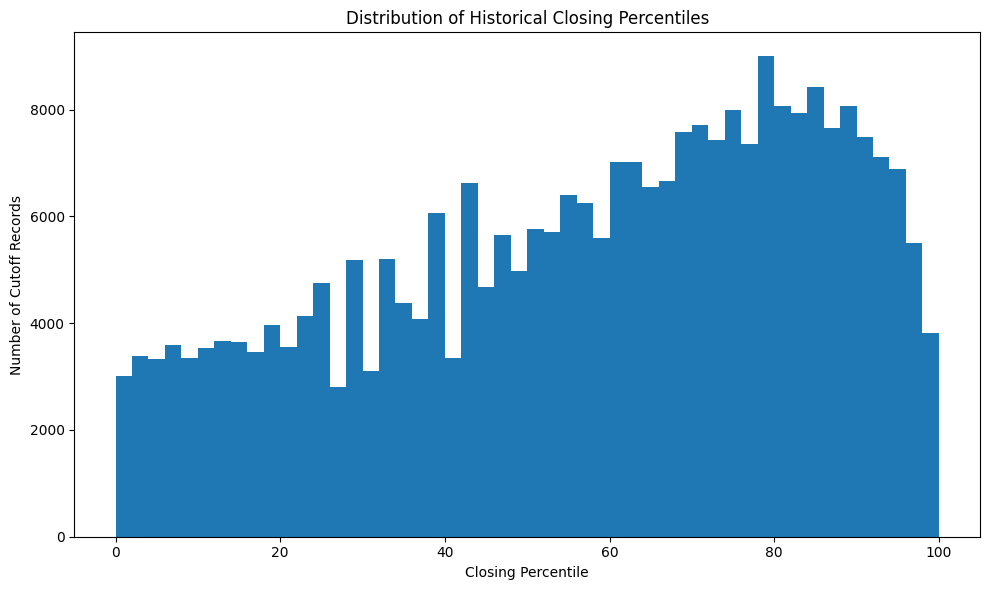

In [31]:
print(
    cutoff["ClosingPercentile"].describe()
)

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.hist(
    cutoff["ClosingPercentile"].dropna(),
    bins=50
)

plt.xlabel("Closing Percentile")
plt.ylabel("Number of Cutoff Records")
plt.title("Distribution of Historical Closing Percentiles")

plt.tight_layout()
plt.show()

In [32]:
year_summary = (
    cutoff
    .groupby("Year")
    .agg(
        CutoffRecords=("ClosingPercentile", "size"),
        MeanClosingPercentile=("ClosingPercentile", "mean"),
        MedianClosingPercentile=("ClosingPercentile", "median"),
        MinClosingPercentile=("ClosingPercentile", "min"),
        MaxClosingPercentile=("ClosingPercentile", "max")
    )
    .reset_index()
)

display(year_summary)

,Year,CutoffRecords,MeanClosingPercentile,MedianClosingPercentile,MinClosingPercentile,MaxClosingPercentile
0,2022,48914,55.254356,59.419246,0.004739,99.914865
1,2023,55704,57.559425,61.688126,0.004054,99.970071
2,2024,76995,57.535923,61.326171,0.000000,100.000000
3,2025,96888,58.608827,62.918458,0.000000,99.954370


In [33]:
round_summary = (
    cutoff
    .groupby(["Year", "CAPRound"])
    .agg(
        CutoffRecords=("ClosingPercentile", "size"),
        MeanClosingPercentile=("ClosingPercentile", "mean"),
        MedianClosingPercentile=("ClosingPercentile", "median")
    )
    .reset_index()
)

display(round_summary)

,Year,CAPRound,CutoffRecords,MeanClosingPercentile,MedianClosingPercentile
0,2022,I,20576,55.299718,59.701546
1,2022,II,17894,55.331063,58.811337
2,2022,III,10444,55.033565,58.811337
3,2023,I,23064,57.489875,62.734434
4,2023,II,20500,57.367733,61.639764
5,2023,III,12140,58.015257,61.639764
6,2024,I,30615,58.124502,62.835169
7,2024,II,29997,56.750470,60.292154
8,2024,III,16383,57.874193,61.635467
9,2025,I,33268,58.227875,62.918458


In [34]:
round_order = {
    "I": 1,
    "II": 2,
    "III": 3,
    "IV": 4
}

cutoff["RoundNumber"] = cutoff["CAPRound"].map(
    round_order
)

cutoff = cutoff.sort_values(
    [
        "Year",
        "CollegeID",
        "BranchID",
        "Category",
        "Stage",
        "RoundNumber"
    ]
)

historical_keys = [
    "Year",
    "CollegeID",
    "BranchID",
    "Category",
    "Stage"
]

cutoff["PreviousClosingPercentile"] = (
    cutoff
    .groupby(historical_keys)["ClosingPercentile"]
    .shift(1)
)

cutoff["CAPRoundChange"] = (
    cutoff["ClosingPercentile"]
    - cutoff["PreviousClosingPercentile"]
)

display(
    cutoff[
        [
            "Year",
            "CAPRound",
            "CollegeName",
            "BranchName",
            "Category",
            "ClosingPercentile",
            "PreviousClosingPercentile",
            "CAPRoundChange"
        ]
    ].head(50)
)

,Year,CAPRound,CollegeName,BranchName,Category,ClosingPercentile,PreviousClosingPercentile,CAPRoundChange
0,2022,I,"Government College of Engineering, Amravati",Civil Engineering,DEFOPENS,42.794675,NaN,NaN
20576,2022,II,"Government College of Engineering, Amravati",Civil Engineering,DEFOPENS,51.235901,42.794675,8.441226
38470,2022,III,"Government College of Engineering, Amravati",Civil Engineering,DEFOPENS,70.937084,NaN,NaN
1,2022,I,"Government College of Engineering, Amravati",Civil Engineering,DEFROBCS,32.499271,NaN,NaN
2,2022,I,"Government College of Engineering, Amravati",Civil Engineering,EWS,70.213583,NaN,NaN
20577,2022,II,"Government College of Engineering, Amravati",Civil Engineering,EWS,57.716502,70.213583,-12.497081
38471,2022,III,"Government College of Engineering, Amravati",Civil Engineering,EWS,67.482418,57.716502,9.765916
3,2022,I,"Government College of Engineering, Amravati",Civil Engineering,GNT1S,77.066692,NaN,NaN
20578,2022,II,"Government College of Engineering, Amravati",Civil Engineering,GNT1S,68.702400,77.066692,-8.364291
38472,2022,III,"Government College of Engineering, Amravati",Civil Engineering,GNT1S,69.039484,68.702400,0.337083


In [35]:
yearly = cutoff.sort_values(
    [
        "CollegeID",
        "BranchID",
        "Category",
        "Stage",
        "Year",
        "RoundNumber"
    ]
)

yearly["PreviousYearClosingPercentile"] = (
    yearly
    .groupby(
        [
            "CollegeID",
            "BranchID",
            "Category",
            "Stage",
            "CAPRound"
        ]
    )["ClosingPercentile"]
    .shift(1)
)

yearly["YearOverYearChange"] = (
    yearly["ClosingPercentile"]
    - yearly["PreviousYearClosingPercentile"]
)

display(
    yearly[
        [
            "Year",
            "CAPRound",
            "CollegeName",
            "BranchName",
            "Category",
            "ClosingPercentile",
            "PreviousYearClosingPercentile",
            "YearOverYearChange"
        ]
    ].head(50)
)

,Year,CAPRound,CollegeName,BranchName,Category,ClosingPercentile,PreviousYearClosingPercentile,YearOverYearChange
104618,2024,I,"Government College of Engineering, Amravati",Civil Engineering,DEFOBCS,47.984280,NaN,NaN
181613,2025,I,"Government College of Engineering, Amravati",Civil Engineering,DEFOBCS,73.261286,47.984280,25.277007
0,2022,I,"Government College of Engineering, Amravati",Civil Engineering,DEFOPENS,42.794675,NaN,NaN
20576,2022,II,"Government College of Engineering, Amravati",Civil Engineering,DEFOPENS,51.235901,NaN,NaN
48914,2023,I,"Government College of Engineering, Amravati",Civil Engineering,DEFOPENS,36.161963,42.794675,-6.632712
71978,2023,II,"Government College of Engineering, Amravati",Civil Engineering,DEFOPENS,76.046398,51.235901,24.810497
104619,2024,I,"Government College of Engineering, Amravati",Civil Engineering,DEFOPENS,67.045836,36.161963,30.883873
181614,2025,I,"Government College of Engineering, Amravati",Civil Engineering,DEFOPENS,85.850125,67.045836,18.804289
38470,2022,III,"Government College of Engineering, Amravati",Civil Engineering,DEFOPENS,70.937084,NaN,NaN
1,2022,I,"Government College of Engineering, Amravati",Civil Engineering,DEFROBCS,32.499271,NaN,NaN


In [36]:
historical_range = (
    cutoff
    .groupby(
        [
            "CollegeID",
            "CollegeCode",
            "CollegeName",
            "BranchID",
            "BranchCode",
            "BranchName",
            "Category",
            "BaseCategory",
            "SeatType",
            "LocationType",
            "SpecialQuota",
            "Stage"
        ],
        dropna=False
    )
    .agg(
        YearsAvailable=("Year", "nunique"),

        HistoricalLowestCutoff=(
            "ClosingPercentile",
            "min"
        ),

        HistoricalHighestCutoff=(
            "ClosingPercentile",
            "max"
        ),

        AverageCutoff=(
            "ClosingPercentile",
            "mean"
        ),

        MedianCutoff=(
            "ClosingPercentile",
            "median"
        ),

        LatestYear=("Year", "max")
    )
    .reset_index()
)

historical_range["HistoricalCutoffRange"] = (
    historical_range["HistoricalHighestCutoff"]
    -
    historical_range["HistoricalLowestCutoff"]
)

display(historical_range.head(30))

,CollegeID,CollegeCode,CollegeName,BranchID,BranchCode,BranchName,Category,BaseCategory,SeatType,LocationType,SpecialQuota,Stage,YearsAvailable,HistoricalLowestCutoff,HistoricalHighestCutoff,AverageCutoff,MedianCutoff,LatestYear,HistoricalCutoffRange
0,COL_1002,1002,"Government College of Engineering, Amravati",BR_100219110,100219110,Civil Engineering,DEFOBCS,OBCS,DEFENCE,General,DEFENCE,I,2,47.984280,73.261286,60.622783,60.622783,2025,25.277007
1,COL_1002,1002,"Government College of Engineering, Amravati",BR_100219110,100219110,Civil Engineering,DEFOPENS,OPENS,DEFENCE,General,DEFENCE,I,4,36.161963,85.850125,59.855816,59.140869,2025,49.688163
2,COL_1002,1002,"Government College of Engineering, Amravati",BR_100219110,100219110,Civil Engineering,DEFOPENS,OPENS,DEFENCE,General,DEFENCE,I-Non Defence,1,70.937084,70.937084,70.937084,70.937084,2022,0.000000
3,COL_1002,1002,"Government College of Engineering, Amravati",BR_100219110,100219110,Civil Engineering,DEFROBCS,OBCS,DEFENCE,Regional,DEFENCE,I,3,20.319899,77.163157,49.770057,50.798587,2025,56.843258
4,COL_1002,1002,"Government College of Engineering, Amravati",BR_100219110,100219110,Civil Engineering,DEFRSEBCS,SEBCS,DEFENCE,Regional,DEFENCE,I,1,50.634076,50.634076,50.634076,50.634076,2024,0.000000
5,COL_1002,1002,"Government College of Engineering, Amravati",BR_100219110,100219110,Civil Engineering,EWS,EWS,EWS,NaN,EWS,I,4,53.742449,88.680102,70.740773,70.844554,2025,34.937653
6,COL_1002,1002,"Government College of Engineering, Amravati",BR_100219110,100219110,Civil Engineering,GNT1S,NT1,REGULAR,General,NaN,I,4,68.702400,88.442613,78.614347,77.066692,2025,19.740213
7,COL_1002,1002,"Government College of Engineering, Amravati",BR_100219110,100219110,Civil Engineering,GNT2S,NT2,REGULAR,General,NaN,I,4,70.213583,87.687217,79.064857,79.808121,2025,17.473634
8,COL_1002,1002,"Government College of Engineering, Amravati",BR_100219110,100219110,Civil Engineering,GNT3S,NT3,REGULAR,General,NaN,I,4,59.529233,87.894547,74.985110,74.193548,2025,28.365314
9,COL_1002,1002,"Government College of Engineering, Amravati",BR_100219110,100219110,Civil Engineering,GOBCS,OBC,REGULAR,General,NaN,I,4,74.096211,87.952609,81.800027,82.165030,2025,13.856397


In [37]:
latest_year = cutoff["Year"].max()

latest_cutoffs = cutoff[
    cutoff["Year"] == latest_year
].copy()

print("Latest year:", latest_year)
print("Latest cutoff records:", len(latest_cutoffs))

display(latest_cutoffs.head(20))

Latest year: 2025
Latest cutoff records: 96888


,Year,CAPRound,CollegeID,CollegeCode,CollegeName,BranchID,BranchCode,BranchName,Category,BaseCategory,...,MedianPercentile,OpeningRank,ClosingRank,MedianRank,AcademicYear,PercentileSpread,RankSpread,RoundNumber,PreviousClosingPercentile,CAPRoundChange
181613,2025,I,COL_1002,1002,"Government College of Engineering, Amravati",BR_100219110,100219110,Civil Engineering,DEFOBCS,OBCS,...,73.261286,85223,85223,85223.0,2025-26,0.0,0,1,NaN,NaN
181614,2025,I,COL_1002,1002,"Government College of Engineering, Amravati",BR_100219110,100219110,Civil Engineering,DEFOPENS,OPENS,...,85.850125,47707,47707,47707.0,2025-26,0.0,0,1,NaN,NaN
181615,2025,I,COL_1002,1002,"Government College of Engineering, Amravati",BR_100219110,100219110,Civil Engineering,DEFROBCS,OBCS,...,69.097902,95765,95765,95765.0,2025-26,0.0,0,1,NaN,NaN
214881,2025,II,COL_1002,1002,"Government College of Engineering, Amravati",BR_100219110,100219110,Civil Engineering,DEFROBCS,OBCS,...,77.163157,73224,73224,73224.0,2025-26,0.0,0,2,69.097902,8.065254
181616,2025,I,COL_1002,1002,"Government College of Engineering, Amravati",BR_100219110,100219110,Civil Engineering,EWS,EWS,...,71.475525,90389,90389,90389.0,2025-26,0.0,0,1,NaN,NaN
214882,2025,II,COL_1002,1002,"Government College of Engineering, Amravati",BR_100219110,100219110,Civil Engineering,EWS,EWS,...,88.680102,38374,38374,38374.0,2025-26,0.0,0,2,71.475525,17.204577
181617,2025,I,COL_1002,1002,"Government College of Engineering, Amravati",BR_100219110,100219110,Civil Engineering,GNT1S,NT1,...,85.572915,48422,48422,48422.0,2025-26,0.0,0,1,NaN,NaN
247456,2025,III,COL_1002,1002,"Government College of Engineering, Amravati",BR_100219110,100219110,Civil Engineering,GNT1S,NT1,...,85.191956,49466,49466,49466.0,2025-26,0.0,0,3,85.572915,-0.380959
181618,2025,I,COL_1002,1002,"Government College of Engineering, Amravati",BR_100219110,100219110,Civil Engineering,GNT2S,NT2,...,87.687217,41549,41549,41549.0,2025-26,0.0,0,1,NaN,NaN
265060,2025,IV,COL_1002,1002,"Government College of Engineering, Amravati",BR_100219110,100219110,Civil Engineering,GNT2S,NT2,...,83.205858,55787,55787,55787.0,2025-26,0.0,0,4,87.687217,-4.481359


In [38]:
final_columns = [
    "Year",
    "AcademicYear",
    "CAPRound",

    "CollegeID",
    "CollegeCode",
    "CollegeName",

    "BranchID",
    "BranchCode",
    "BranchName",

    "Category",
    "BaseCategory",
    "SeatType",
    "LocationType",
    "SpecialQuota",
    "Stage",

    "Records",

    "OpeningPercentile",
    "ClosingPercentile",
    "MedianPercentile",

    "OpeningRank",
    "ClosingRank",
    "MedianRank",

    "PercentileSpread",
    "RankSpread"
]

historical_cutoffs = cutoff[final_columns].copy()

print(
    "FINAL HISTORICAL CUTOFF TABLE:",
    historical_cutoffs.shape
)

display(historical_cutoffs.head(20))

FINAL HISTORICAL CUTOFF TABLE: (278501, 24)


,Year,AcademicYear,CAPRound,CollegeID,CollegeCode,CollegeName,BranchID,BranchCode,BranchName,Category,...,Stage,Records,OpeningPercentile,ClosingPercentile,MedianPercentile,OpeningRank,ClosingRank,MedianRank,PercentileSpread,RankSpread
0,2022,2022-23,I,COL_1002,1002,"Government College of Engineering, Amravati",BR_100219110,100219110,Civil Engineering,DEFOPENS,...,I,1,42.794675,42.794675,42.794675,88218,88218,88218.0,0.0,0
20576,2022,2022-23,II,COL_1002,1002,"Government College of Engineering, Amravati",BR_100219110,100219110,Civil Engineering,DEFOPENS,...,I,1,51.235901,51.235901,51.235901,78568,78568,78568.0,0.0,0
38470,2022,2022-23,III,COL_1002,1002,"Government College of Engineering, Amravati",BR_100219110,100219110,Civil Engineering,DEFOPENS,...,I-Non Defence,1,70.937084,70.937084,70.937084,51661,51661,51661.0,0.0,0
1,2022,2022-23,I,COL_1002,1002,"Government College of Engineering, Amravati",BR_100219110,100219110,Civil Engineering,DEFROBCS,...,I,1,32.499271,32.499271,32.499271,98060,98060,98060.0,0.0,0
2,2022,2022-23,I,COL_1002,1002,"Government College of Engineering, Amravati",BR_100219110,100219110,Civil Engineering,EWS,...,I,1,70.213583,70.213583,70.213583,52672,52672,52672.0,0.0,0
20577,2022,2022-23,II,COL_1002,1002,"Government College of Engineering, Amravati",BR_100219110,100219110,Civil Engineering,EWS,...,I,1,57.716502,57.716502,57.716502,69892,69892,69892.0,0.0,0
38471,2022,2022-23,III,COL_1002,1002,"Government College of Engineering, Amravati",BR_100219110,100219110,Civil Engineering,EWS,...,I,1,67.482418,67.482418,67.482418,56495,56495,56495.0,0.0,0
3,2022,2022-23,I,COL_1002,1002,"Government College of Engineering, Amravati",BR_100219110,100219110,Civil Engineering,GNT1S,...,I,1,77.066692,77.066692,77.066692,41586,41586,41586.0,0.0,0
20578,2022,2022-23,II,COL_1002,1002,"Government College of Engineering, Amravati",BR_100219110,100219110,Civil Engineering,GNT1S,...,I,1,68.702400,68.702400,68.702400,54948,54948,54948.0,0.0,0
38472,2022,2022-23,III,COL_1002,1002,"Government College of Engineering, Amravati",BR_100219110,100219110,Civil Engineering,GNT1S,...,I,1,69.039484,69.039484,69.039484,54700,54700,54700.0,0.0,0


In [39]:
historical_cutoffs.to_csv(
    "MHTCET_Historical_Cutoffs.csv",
    index=False
)

historical_range.to_csv(
    "MHTCET_Historical_Cutoff_Ranges.csv",
    index=False
)

latest_cutoffs.to_csv(
    "MHTCET_Latest_Available_Cutoffs.csv",
    index=False
)

print("All cutoff files saved.")

All cutoff files saved.


In [40]:
print("Missing closing percentile:",
      historical_cutoffs["ClosingPercentile"].isna().sum())

print("Closing percentile = 0:",
      (historical_cutoffs["ClosingPercentile"] == 0).sum())

print("Closing percentile > 100:",
      (historical_cutoffs["ClosingPercentile"] > 100).sum())

print("Closing percentile < 0:",
      (historical_cutoffs["ClosingPercentile"] < 0).sum())

Missing closing percentile: 0
Closing percentile = 0: 62
Closing percentile > 100: 0
Closing percentile < 0: 0
